折线 - BOLD 信号

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#np.random.seed(10)

# =========================
# 1. 时间序列
# =========================
n = 110
x = np.linspace(0, 1, n)

# =========================
# 2. 高频 BOLD-like 信号
# =========================

# 提高主要振荡频率

signal = (
    0.20 * np.sin(2 * np.pi * 18 * x) +
    0.25 * np.sin(2 * np.pi * 28 * x + 0.8) +
    0.10 * np.sin(2 * np.pi * 38 * x + 1.5)
)
# 添加随机波动
noise = 0.35 * np.random.randn(n)

signal = signal + noise

# 稍微平滑，但保持较高频率
kernel = np.array([0.2, 0.6, 0.2])
signal = np.convolve(signal, kernel, mode="same")

# 添加少量明显尖峰
spike_idx = np.random.choice(n, 8, replace=False)
signal[spike_idx] += np.random.uniform(-0.8, 0.8, 8)

# 标准化
signal = signal - np.mean(signal)
signal = signal / np.max(np.abs(signal))


# =========================
# 3. 绘图
# =========================
fig, ax = plt.subplots(figsize=(8, 1.6))

# 水平基线
# ax.plot(
#     [-5, n + 3],
#     [0, 0],
#     color="black",
#     linewidth=1
# )

# BOLD 信号
ax.plot(
    np.arange(n),
    signal,
    color="#0F6FB8", #   #0F6FB8 #09A58B   #9DA2A4
    linewidth=5
)

# 时间方向箭头
# ax.annotate(
#     "",
#     xy=(n + 5, 0),
#     xytext=(n + 1, 0),
#     arrowprops=dict(
#         arrowstyle="-|>",
#         color="black",
#         lw=1.5,
#         mutation_scale=22
#     )
# )

# 美化
ax.set_xlim(-5, n + 8)
ax.set_ylim(-1.25, 1.25)
ax.axis("off")

plt.tight_layout()
#
# plt.savefig(
#     "high_frequency_BOLD_signal.png",
#     dpi=300,
#     bbox_inches="tight",
#     transparent=True
# )
# JPG：白色背景
plt.savefig(
    "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/signal_a.svg",
    bbox_inches="tight",
    transparent=True,
    pad_inches=0
)
plt.show()


热图

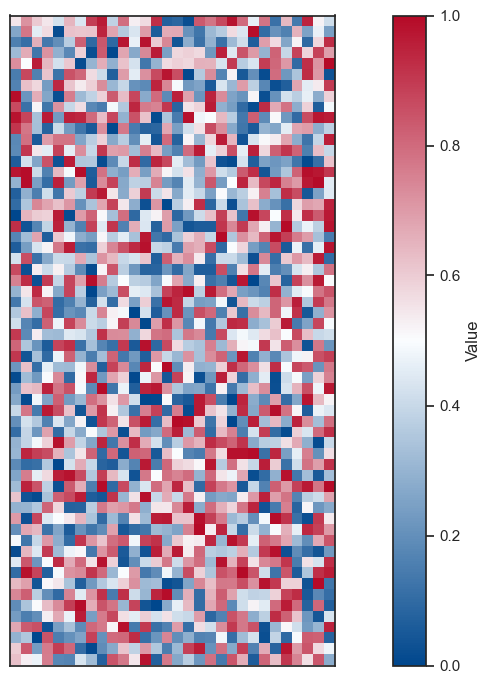

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

n_rows = 60
n_cols = 30

custom_colors = ["#00478D", "#7DA2C6", "#FAFDFF", "#D78393", "#B50A27"]
my_cmap = LinearSegmentedColormap.from_list("heat_custom", custom_colors, N=256)

np.random.seed(0)
heat_data = np.random.rand(n_rows, n_cols)

fig, ax = plt.subplots(figsize=(12,7))
im = ax.imshow(heat_data, cmap=my_cmap, vmin=0, vmax=1,aspect="equal")

# colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Value")

# 隐藏坐标轴刻度（可选）
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.savefig("/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/hotmap.png", dpi=300, bbox_inches="tight")
plt.show()


ACF 折线图

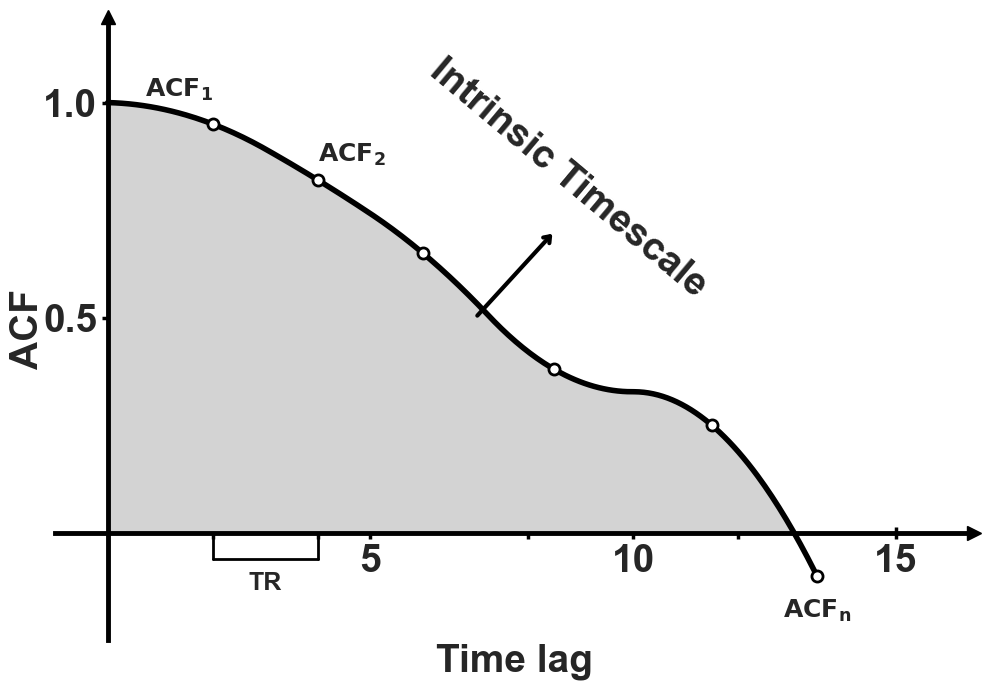

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# 1. Define approximate data points based on the image
x_points = np.array([0, 2, 4, 6, 8.5, 11.5, 13.5])
y_points = np.array([1.0, 0.95, 0.82, 0.65, 0.38, 0.25, -0.1])

# Generate a smooth curve using spline interpolation
x_smooth = np.linspace(x_points.min(), x_points.max(), 300)
spl = make_interp_spline(x_points, y_points, k=2)
y_smooth = spl(x_smooth)

# 2. Setup figure and axes
fig, ax = plt.subplots(figsize=(10, 7))

# Set background to white
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# 3. Plot the filled area and the main curve
# ----- 修改点 1：将阴影换成浅灰色 ('lightgray') -----
ax.fill_between(x_smooth, y_smooth, 0, where=(y_smooth >= 0), color='lightgray', zorder=1)
ax.plot(x_smooth, y_smooth, color='black', linewidth=4, zorder=2)

# 4. Plot the markers (ignoring the first invisible point at x=0)
ax.plot(x_points[1:], y_points[1:], 'o', markerfacecolor='white',
        markeredgecolor='black', markeredgewidth=2, markersize=8, zorder=3)

# 5. Format axes (Thick lines, centered at zero, hidden top/right bounds)
ax.spines['left'].set_position('zero')
ax.spines['left'].set_linewidth(3.5)
ax.spines['left'].set_color('black')

ax.spines['bottom'].set_position('zero')
ax.spines['bottom'].set_linewidth(3.5)
ax.spines['bottom'].set_color('black')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Add custom arrowheads to the end of the axes
ax.plot(1, 0, ">k", transform=ax.get_yaxis_transform(), clip_on=False, markersize=10)
ax.plot(0, 1, "^k", transform=ax.get_xaxis_transform(), clip_on=False, markersize=10)

# Set axis limits
ax.set_xlim(-1, 16.5)
ax.set_ylim(-0.25, 1.2)

# 6. Customize ticks
ax.set_xticks([2, 4, 5, 8, 10, 12, 15])
ax.set_xticklabels(['', '', '5', '', '10', '', '15'], fontweight='bold', fontsize=28)
ax.set_yticks([0.5, 1.0])
ax.set_yticklabels(['0.5', '1.0'], fontweight='bold', fontsize=28)

# ----- 修改点 2：明确显示坐标轴刻度，并设置粗细同坐标轴 (width=2.5) -----
ax.tick_params(axis='both', which='major', width=2.5, length=8, direction='inout',
               color='black', bottom=True, left=True)

# 7. Add Labels and Titles
ax.set_xlabel('Time lag', fontweight='bold', fontsize=28,fontfamily='Arial')
ax.set_ylabel('ACF', fontweight='bold', fontsize=28,fontfamily='Arial')
ax.xaxis.set_label_coords(0.5, -0.005)
ax.yaxis.set_label_coords(-0.01, 0.5)

# 8. Annotations
# ACF marker labels
ax.text(2, 1.0 ,r'$\mathbf{ACF_1}$', ha='right', va='bottom', fontsize=18)
ax.text(4, 0.85, r'$\mathbf{ACF_2}$', ha='left', va='bottom', fontsize=18)
ax.text(13.5, -0.15, r'$\mathbf{ACF_n}$', ha='center', va='top', fontsize=18)

# "Intrinsic Timescale" text and arrow
ax.annotate('', xy=(8.5, 0.70), xytext=(7.0, 0.50),
            arrowprops=dict(arrowstyle='->, head_width=0.3, head_length=0.4', lw=3, color='black'))
ax.text(6.0, 0.55, 'Intrinsic Timescale', rotation=-40, fontweight='bold', fontsize=28)

# "TR" Bracket (Drawn manually for square precise lines below the axis)
ax.plot([2, 4], [-0.06, -0.06], color='black', lw=2, clip_on=False)
ax.plot([2, 2], [-0.06, -0.01], color='black', lw=2, clip_on=False)
ax.plot([4, 4], [-0.06, -0.01], color='black', lw=2, clip_on=False)
ax.text(3, -0.09, 'TR', ha='center', va='top', fontweight='bold', fontsize=18)

# Render the plot
plt.tight_layout()
plt.savefig("/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/ACF.png", dpi=300, bbox_inches="tight", facecolor='white')
plt.show()

=== 协方差分析 (ANCOVA) 结果 ===
             sum_sq     df          F    PR(>F)
C(Group)   0.466929    1.0   5.550273  0.018831
C(sex)     0.055820    1.0   0.663524  0.415674
age        0.036517    1.0   0.434073  0.510275
mean_fd    1.231027    1.0  14.632912  0.000146
Residual  45.849351  545.0        NaN       NaN

控制年龄、性别和头动(mean_fd)后，组间差异的真实 P 值: 1.883101e-02


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_49956/2816406191.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_49956/2816406191.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


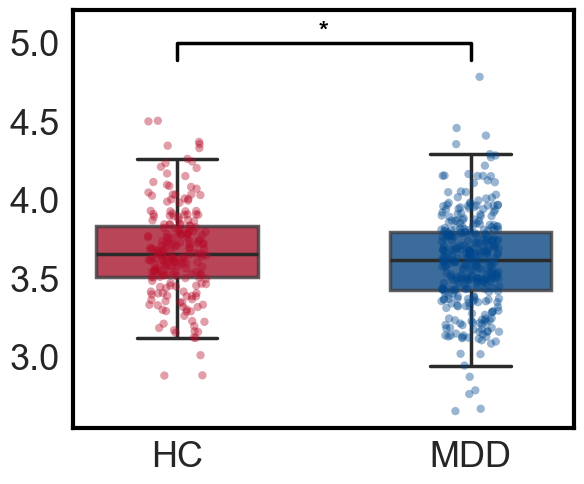

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

# ==========================================
# 1. 读取数据与合并
# ==========================================
df_s1 = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/HC_mean_INT_agesex_FD.csv'
)
df_s2 = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/MDD_mean_INT_agesex_FD.csv'
)

df_s1['Group'] = 'HC'
df_s2['Group'] = 'MDD'

df = pd.concat([df_s1, df_s2], ignore_index=True)
df = df[['Group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# ==========================================
# 2. 广义线性模型 (GLM) / 协方差分析 (ANCOVA)
# ==========================================
formula = 'mean_INT ~ C(Group) + age + C(sex) + mean_fd'
model = ols(formula, data=df).fit()

anova_table = sm.stats.anova_lm(model, typ=2)
print('=== 协方差分析 (ANCOVA) 结果 ===')
print(anova_table)

target_param = 'C(Group)[T.MDD]'
p_val = model.pvalues.get(target_param, np.nan)
t_val = model.tvalues.get(target_param, np.nan)
print(f'\n控制年龄、性别和头动(mean_fd)后，组间差异的真实 P 值: {p_val:.6e}')

# ==========================================
# 3. 绘制并动态智能标注显著性的箱体图
# ==========================================
plt.figure(figsize=(6, 5))

# 设置画板背景为白色
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义颜色字典：HC 为 #42B8B1，MDD 为 #6AB4DC
palette_colors = {'HC': '#B50A27', 'MDD': '#00478D'}

# 绘制箱体图（通过 linewidth 调粗箱体线条）
ax = sns.boxplot(
    x='Group',
    y='mean_INT',
    data=df,
    order=['HC', 'MDD'],
    palette=palette_colors,
    width=0.55,
    showfliers=False,
    saturation=.85,
    linewidth=2.5,  # 调粗箱体线条
    boxprops={'alpha': 0.8,'edgecolor': '#3C3B3D'},
    # 是否保留箱体的线条
)

# 绘制散点图（通过 size 调大散点圆的大小）
sns.stripplot(
    x='Group',
    y='mean_INT',
    data=df,
    order=['HC', 'MDD'],
    #color='black',
    palette=palette_colors,
    alpha=0.4,
    size=6,  # 调大散点圆的大小
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(3)
  spine.set_visible(True)

# 计算画线位置
y_max = df['mean_INT'].max()
y_range = df['mean_INT'].max() - df['mean_INT'].min()
h = y_range * 0.05
line_y = y_max + h

# 如果 p_val < 0.05，则绘制连线和星号
if p_val < 0.05:
  x1, x2 = 0, 1
  plt.plot(
      [x1, x1, x2, x2],
      [line_y, line_y + h, line_y + h, line_y],
      lw=2.5,
      c='black',
  )

  if p_val < 0.001:
    stars = '***'
  elif p_val < 0.01:
    stars = '**'
  else:
    stars = '*'

  plt.text(
      (x1 + x2) * 0.5,
      line_y + h,
      stars,
      ha='center',
      va='bottom',
      color='black',
      fontsize=18,
      fontweight='bold',
  )
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
# 留出顶部空间
plt.ylim(df['mean_INT'].min() - y_range * 0.05, line_y + h * 3)

# 图表标签
plt.ylabel('', fontsize=12)
plt.xlabel('', fontsize=12)
plt.tight_layout()

# 保存图片
out_fig = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/Fig_subtype1_subtype2.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')



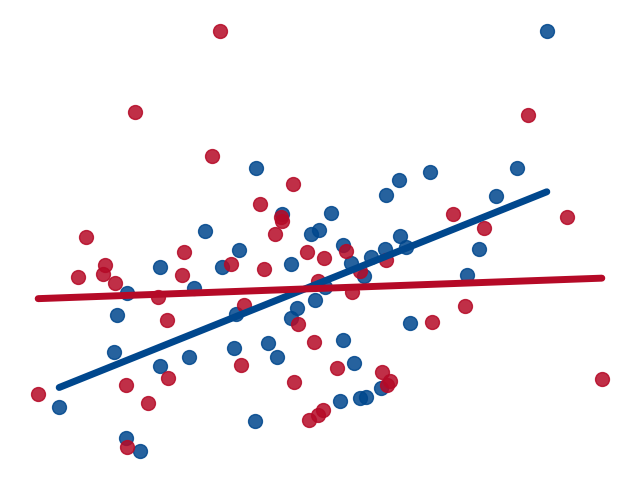

蓝色组实际相关系数 r = 0.545, 回归线斜率 = 0.526


In [24]:
import matplotlib.pyplot as plt
import numpy as np

# 固定随机种子保证结果可复现
np.random.seed(42)

# ----------------------
# 蓝色组：人为设置X‑Y正相关，回归线倾斜更大
# r 相关系数: 0.6 ~ 0.8 倾斜比较明显；最大绝对值为1
# ----------------------
r = 0.65   # <--- 修改这个值，越大相关性越强、回归线越陡
mean = [0, 0]
cov_matrix = [[1, r],
              [r, 1]]
group1_data = np.random.multivariate_normal(mean, cov_matrix, size=50)
group1_x = group1_data[:, 0]
group1_y = group1_data[:, 1]

# 红色组保持原来无相关的随机分布不变
group2_x = np.random.normal(loc=0, scale=1, size=50)
group2_y = np.random.normal(loc=0, scale=1, size=50)

# ==========================
# 可调节参数：颜色、散点大小与透明度
# ==========================
color1 = '#00478D'
color2 = '#B50A27'
point_size = 100
point_alpha = 0.85
# ==========================

# 创建画布和坐标系
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_facecolor("white")  # 坐标轴区域背景白色
# 绘制散点图
ax.scatter(group1_x, group1_y, c=color1, s=point_size, alpha=point_alpha)
ax.scatter(group2_x, group2_y, c=color2, s=point_size, alpha=point_alpha)

# ==========================
# 分别为两组数据计算并绘制回归线
# ==========================
# 蓝色回归线
slope1, intercept1 = np.polyfit(group1_x, group1_y, 1)
x_fit1 = np.linspace(group1_x.min(), group1_x.max(), 100)
y_fit1 = slope1 * x_fit1 + intercept1
ax.plot(x_fit1, y_fit1, color=color1, linestyle='-', linewidth=5)

# 红色回归线
slope2, intercept2 = np.polyfit(group2_x, group2_y, 1)
x_fit2 = np.linspace(group2_x.min(), group2_x.max(), 100)
y_fit2 = slope2 * x_fit2 + intercept2
ax.plot(x_fit2, y_fit2, color=color2, linestyle='-', linewidth=5)

# ==========================
# 去除上下左右四条边框线
# ==========================
for spine in ['top', 'bottom', 'left', 'right']:
    ax.spines[spine].set_visible(False)

# 隐藏坐标轴刻度（可选，通常无边框图也不需要刻度）
ax.set_xticks([])
ax.set_yticks([])

ax.grid(False)
ax.set_xlabel('')
ax.set_ylabel('')

# 保存图片
out_fig = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/scatter.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

# 打印实际相关系数与斜率，方便你查看效果
corr_blue = np.corrcoef(group1_x, group1_y)[0, 1]
print(f"蓝色组实际相关系数 r = {corr_blue:.3f}, 回归线斜率 = {slope1:.3f}")


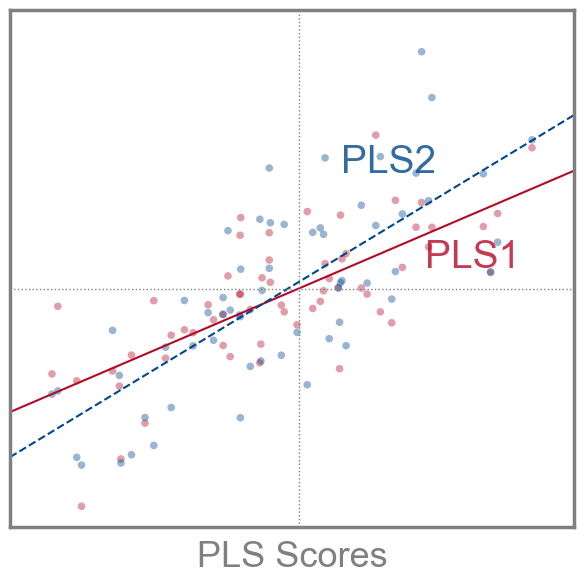

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# 设置随机种子以保证每次生成的数据相同
np.random.seed(42)

# ==========================================
# 1. 生成模拟数据
# ==========================================
n_points = 60
# 生成 X 轴基础数据 (围绕 0 随机分布)
x = np.random.normal(loc=0, scale=1.5, size=n_points)

# 生成 PLS1 数据 (红色，具有正相关性，加一些噪声)
y1 = 0.8 * x + np.random.normal(loc=0, scale=1.2, size=n_points)
# 生成 PLS2 数据 (蓝色，斜率稍大，加一些噪声)
y2 = 1.1 * x + np.random.normal(loc=0, scale=1.5, size=n_points)

# 指定您需要的颜色
color_pls1 = '#B50A27'  # 深红色
color_pls2 = '#00478D'  # 深蓝色

# ==========================================
# 2. 绘制图表
# ==========================================
fig, ax = plt.subplots(figsize=(6, 6))

# 绘制散点 (alpha 调整透明度使其看起来更像原图)
ax.scatter(x, y1, color=color_pls1, alpha=0.4, edgecolors='none', s=30)
ax.scatter(x, y2, color=color_pls2, alpha=0.4, edgecolors='none', s=30)

# 计算线性回归拟合直线 (1阶多项式)
m1, b1 = np.polyfit(x, y1, 1)
m2, b2 = np.polyfit(x, y2, 1)

# 生成拟合直线的 x 范围
x_line = np.linspace(x.min() - 0.5, x.max() + 0.5, 100)

# 绘制拟合直线
# PLS1 为实线 (solid)
ax.plot(x_line, m1*x_line + b1, color=color_pls1, linestyle='-', linewidth=1.5)
# PLS2 为虚线 (dashed)
ax.plot(x_line, m2*x_line + b2, color=color_pls2, linestyle='--', linewidth=1.5)

# ==========================================
# 3. 添加参考线、标签和样式
# ==========================================
# 添加原点十字参考线 (横向虚线，纵向实线)
ax.axhline(0, color='gray', linestyle=':', linewidth=1)
ax.axvline(0, color='gray', linestyle=':', linewidth=1)

# 添加文字标签 "PLS1" 和 "PLS2"
# (坐标可以根据您实际的数据分布进行微调)
ax.text(1.5, m1*1.5 + b1 - 0.8, 'PLS1', color=color_pls1, fontsize=28, alpha=0.8)
ax.text(0.5, m2*0.5 + b2 + 2.0, 'PLS2', color=color_pls2, fontsize=28, alpha=0.8)

# 底部全局标签
ax.set_xlabel('PLS Scores', fontsize=26, color='gray', labelpad=10)

# 移除刻度标记 (使其和参考图一样简洁)
ax.set_xticks([])
ax.set_yticks([])

# ==========================================
# 修改部分：设置坐标轴边框颜色为灰色，并加粗
# ==========================================
for spine in ax.spines.values():
    spine.set_color('gray')      # 修改为灰色 (也可以用 '#808080')
    spine.set_linewidth(2.5)     # 加粗线条，数值越大越粗

# 限制坐标轴范围以便居中
ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
ax.set_ylim(min(y1.min(), y2.min()) - 0.5, max(y1.max(), y2.max()) + 1.0)


# 显示图像
plt.tight_layout()

out_fig = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/scatter_PLS.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')

plt.show()

选择 K=2 的一个折线示意图

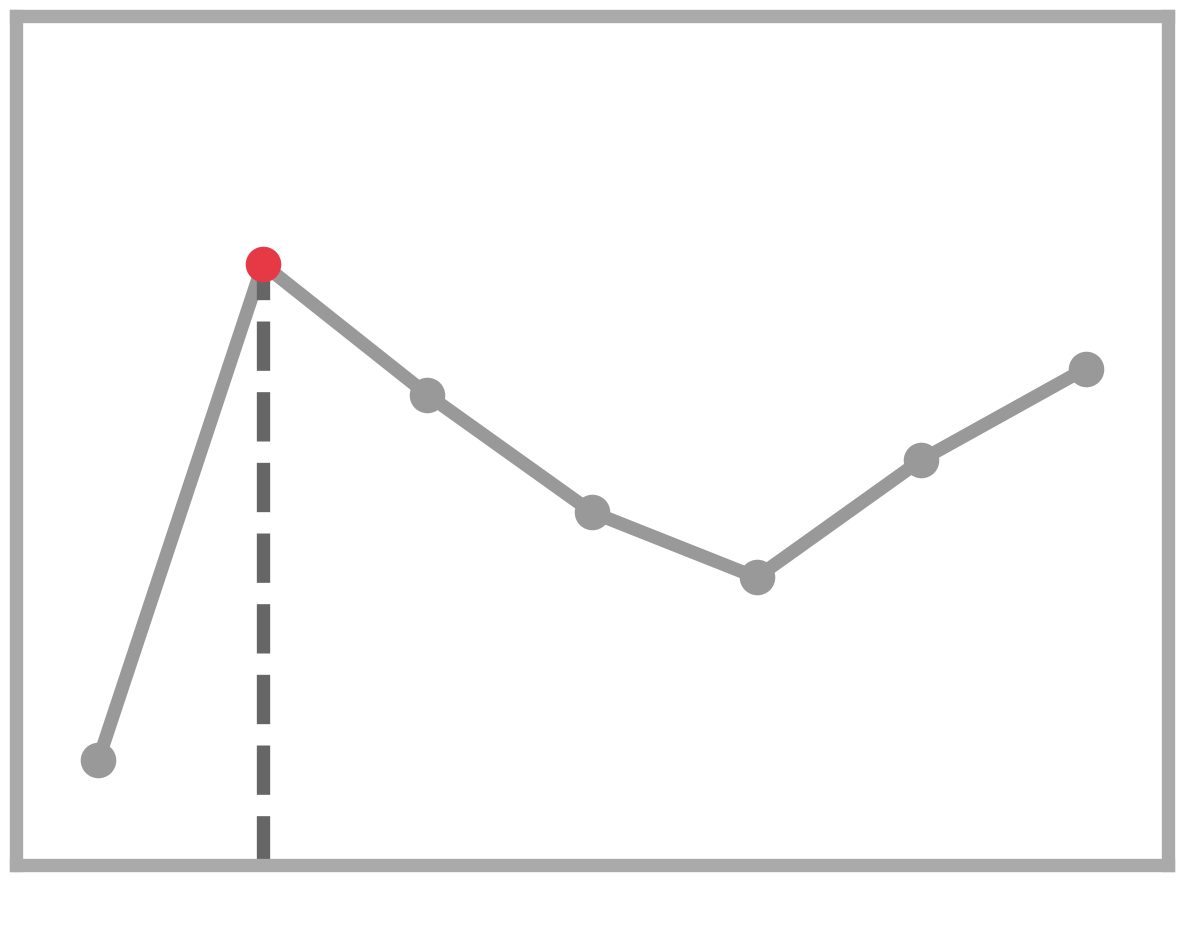

图片已保存：/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/K_curve_gray.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. 数据
# =========================
K = np.arange(1, 8)  # K=2 时达到最大值
y = np.array([0.08,0.46,0.36,0.27,0.22,0.31,0.38])

# =========================
# 2. 可调参数
# =========================
# 背景颜色 - 纯白色
bg_color = "#FFFFFF"
# 普通折线、圆点颜色
line_color = "#999999"
# 峰值点红色
peak_color = "#E63946"
# 坐标轴边框颜色
spine_color = "#AAAAAA"
# 垂向虚线参数
dash_color = "#666666"
dash_width = 2       # 虚线粗细，可自行修改
dash_style = "--"

# 折线粗细
line_width = 6
# 坐标轴边框粗细
spine_width = 6
# 数据点大小
marker_size = 15

# =========================
# 3. 创建画布
# =========================
fig, ax = plt.subplots(
    figsize=(7.5, 6.0),
    dpi=160
)

# 整个画布背景
fig.patch.set_facecolor(bg_color)
# 坐标轴内部背景
ax.set_facecolor(bg_color)

# =========================
# 4. 先画灰色折线（不带圆点）
# =========================
ax.plot(K, y, '-',
        color=line_color,
        linewidth=line_width
        )

# 找出最大值索引
peak_idx = np.argmax(y)
x_peak = K[peak_idx]
y_peak = y[peak_idx]

# 绘制从峰值点垂直向下到 x 轴的虚线
ax.vlines(
    x=x_peak,
    ymin=0,
    ymax=y_peak,
    linestyle=dash_style,
    color=dash_color,
    linewidth=6
)

# 分别绘制普通圆点 和 红色峰值圆点
for i, (xi, yi) in enumerate(zip(K, y)):
    if i == peak_idx:
        ax.plot(xi, yi, 'o',
                markersize=marker_size,
                markerfacecolor=peak_color,
                markeredgecolor=peak_color)
    else:
        ax.plot(xi, yi, 'o',
                markersize=marker_size,
                markerfacecolor=line_color,
                markeredgecolor=line_color)

# =========================
# 5. 坐标轴范围
# =========================
ax.set_xlim(0.5, 7.5)
ax.set_ylim(0, 0.65)

# =========================
# 6. 坐标轴刻度
# =========================
ax.set_xticks(K)
ax.set_yticks(np.arange(0, 0.61, 0.2))

ax.set_xlabel(
    " ",
    fontsize=20,
    labelpad=10
)
ax.set_ylabel("")

# =========================
# 7. 刻度样式
# =========================
ax.tick_params(
    axis='both',
    which='major',
    labelsize=15,
    direction='in',
    length=5,
    width=1.5,
    colors=spine_color,
    labelbottom=False,   # 移除x轴数字
    labelleft=False      # 移除y轴数字
)

# =========================
# 8. 上下左右边框
# =========================
for spine in ax.spines.values():
    spine.set_color(spine_color)
    spine.set_linewidth(spine_width)

# =========================
# 9. 不显示网格
# =========================
ax.grid(False)

# =========================
# 10. 自动调整布局
# =========================
plt.tight_layout()

# =========================
# 11. 保存
# =========================
output_path = (
    "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/K_curve_gray.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"图片已保存：{output_path}")


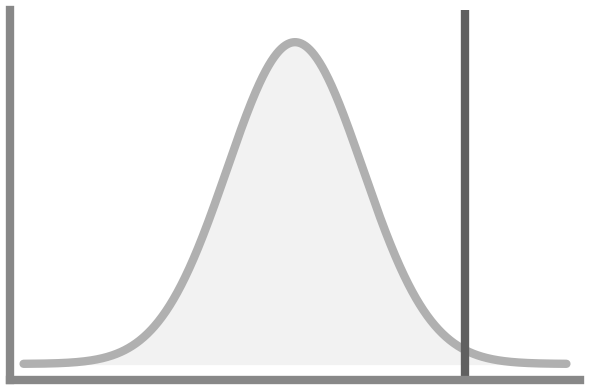

图片已保存：/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/permutationtest_curve_gray.png


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. 生成经验零分布数据 (此处以标准正态分布演示)
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, 0, 1)

# 2. 初始化画布
fig, ax = plt.subplots(figsize=(6, 4))

# 设置画布、绘图区背景为纯白色
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# 3. 绘制平滑曲线与阴影填充
ax.plot(x, y, color='#b0b0b0', linewidth=6)
# 【修改点 1】：显式添加 y2=0 参数。这确保阴影底部绝对平齐于 y=0，不会随着 y 轴下限拉低而“漏底”。
ax.fill_between(x, y, 0, color='#f2f2f2')

# 4. 绘制观测统计量的垂直线
observed_stat = 2.5
ax.axvline(x=observed_stat, color='#606060', linewidth=6)

# 5. 坐标轴与样式美化 (极简无刻度风格)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 设置左轴和底轴为灰色
ax.spines['left'].set_color('#888888')
ax.spines['bottom'].set_color('#888888')
ax.spines['left'].set_linewidth(6)
ax.spines['bottom'].set_linewidth(6)

# 移除刻度标签和刻度线
ax.set_xticks([])
ax.set_yticks([])

# 调整坐标轴范围避免图形边缘留白过多
ax.set_xlim(-4.2, 4.2)

# 【修改点 2】：将 y 轴的极小值设为一个动态的负数（此处为最大高度的 5%）。
# 这会将 x 轴物理基线往下推，从而在 x 轴和曲线底端(y=0)之间留出干净的间距。
y_gap = max(y) * 0.05
ax.set_ylim(-y_gap, max(y) * 1.1)

# 显示图像
plt.tight_layout()

output_path = (
    "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/Main_Plot/permutationtest_curve_gray.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="#FFFFFF"   # 保存图片背景强制白色
)
plt.show()

print(f"图片已保存：{output_path}")